<a href="https://colab.research.google.com/github/keyvanmahmoudi/Deep_Learning_Course/blob/main/sessions/Session13_transformer_from_scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# جلسهٔ ۱۳: Transformer از صفر

### اهداف این جلسه

- درک Self-Attention و نقش Query، Key و Value
- پیاده‌سازی Scaled Dot-Product Attention و Multi-Head Attention از صفر
- آشنایی با Masking علّی (Causal Mask) و رمزگذاری موقعیت (Positional Encoding)
- ساخت بلوک Transformer با LayerNorm، اتصال Residual و شبکه Feed-Forward
- آموزش یک مدل زبانی کوچک شبیه GPT در سطح کاراکتر و تولید متن با Temperature و Top-k

> **نکتهٔ اجرا:** این نوت‌بوک روی GPU بسیار سریع‌تر اجرا می‌شود. در Colab از منوی `Runtime → Change runtime type` گزینهٔ **T4 GPU** را انتخاب کنید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۱. چرا Transformer؟

در جلسه قبل Attention را به Seq2Seq مبتنی بر RNN اضافه کردیم. اما RNN دو مشکل اساسی دارد:

- **پردازش ترتیبی:** محاسبه گام $t$ به گام $t-1$ وابسته است؛ پس نمی‌توان یک دنباله را روی GPU موازی پردازش کرد.
- **مسیر طولانی بین Tokenهای دور:** اطلاعات Token اول باید از $T$ گام عبور کند تا به Token آخر برسد.

**Transformer** (Vaswani et al., 2017) RNN را حذف می‌کند و فقط از **Self-Attention** استفاده می‌کند: هر Token مستقیماً به **همه** Tokenهای دیگر همان دنباله نگاه می‌کند. همه مکان‌ها **همزمان** پردازش می‌شوند و فاصله هر دو Token فقط یک گام است. این معماری پایه BERT، GPT، T5، LLaMA و تقریباً همه مدل‌های زبانی بزرگ امروزی است و در بینایی (Vision Transformer) و صوت هم استفاده می‌شود.

در این جلسه همه اجزای Transformer را از صفر می‌سازیم و در پایان یک **مدل زبانی کوچک شبیه GPT** آموزش می‌دهیم که به سبک شکسپیر متن تولید می‌کند. ساختار کد از پروژه آموزشی nanoGPT آندری کارپاتی الهام گرفته است.

</div>

In [1]:
import math
import time
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)
torch.manual_seed(1337)

device: cpu


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۲. Self-Attention: Query، Key و Value

ایده را با یک قیاس توضیح می‌دهیم: جست‌وجو در یک کتابخانه. هر Token سه بردار می‌سازد:

- **Query** ($\mathbf{q}$): «من دنبال چه اطلاعاتی هستم؟»
- **Key** ($\mathbf{k}$): «من چه اطلاعاتی دارم؟» (برچسب روی جلد کتاب)
- **Value** ($\mathbf{v}$): «اطلاعاتی که در صورت انتخاب شدن تحویل می‌دهم» (محتوای کتاب)

شباهت Query یک Token با Key همه Tokenها (ضرب داخلی) تعیین می‌کند هر کدام چقدر در خروجی آن Token سهم داشته باشند. هر سه بردار با ضرب ورودی $X$ در ماتریس‌های قابل آموزش ساخته می‌شوند: $Q = XW_Q$، $K = XW_K$ و $V = XW_V$. سپس:

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

**چرا تقسیم بر $\sqrt{d_k}$؟** اگر مؤلفه‌های $\mathbf{q}$ و $\mathbf{k}$ مستقل با واریانس ۱ باشند، واریانس ضرب داخلی آن‌ها $d_k$ است. با $d_k$ بزرگ، امتیازها خیلی بزرگ می‌شوند، Softmax اشباع می‌شود (تقریباً One-hot) و گرادیان‌ها تقریباً صفر می‌شوند. تقسیم بر $\sqrt{d_k}$ واریانس را به ۱ برمی‌گرداند.

</div>

In [2]:
def scaled_dot_product_attention(q, k, v, mask=None):
    """q, k, v: (..., T, d). mask: True where attention is NOT allowed."""
    d_k = q.shape[-1]
    scores = q @ k.transpose(-2, -1) / math.sqrt(d_k)          # (..., T, T)
    if mask is not None:
        scores = scores.masked_fill(mask, float('-inf'))
    weights = torch.softmax(scores, dim=-1)
    return weights @ v, weights


T, d = 5, 16
q, k, v = torch.randn(T, d), torch.randn(T, d), torch.randn(T, d)
out, w = scaled_dot_product_attention(q, k, v)
print('output:', tuple(out.shape), '| weights:', tuple(w.shape), '| each row sums to 1:', torch.allclose(w.sum(-1), torch.ones(T)))
print('matches PyTorch:', torch.allclose(out, F.scaled_dot_product_attention(q, k, v), atol=1e-6))

# the effect of the scaling factor
big = torch.randn(1, 512)
keys = torch.randn(10, 512)
print('max softmax weight without scaling:', torch.softmax(big @ keys.T, -1).max().item())
print('max softmax weight with scaling   :', torch.softmax(big @ keys.T / math.sqrt(512), -1).max().item())

output: (5, 16) | weights: (5, 5) | each row sums to 1: True
matches PyTorch: True
max softmax weight without scaling: 0.9952464699745178
max softmax weight with scaling   : 0.2282806932926178


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۳. Masking علّی (Causal Mask)

در یک **مدل زبانی (Language Model)** هدف پیش‌بینی Token بعدی است. اگر Token $t$ بتواند به Tokenهای بعد از خودش نگاه کند، در واقع جواب را می‌بیند و تقلب می‌کند. **ماسک علّی** با قرار دادن $-\infty$ در امتیازهای بالای قطر اصلی، Attention به آینده را ممنوع می‌کند؛ پس از Softmax وزن آن مکان‌ها صفر می‌شود.

مزیت بزرگ: با یک Forward روی دنباله‌ای به طول $T$، مدل **همزمان** $T$ پیش‌بینی (برای هر پیشوند) انجام می‌دهد و از همه آن‌ها برای آموزش استفاده می‌شود.

</div>

In [3]:
causal_mask = torch.triu(torch.ones(T, T, dtype=torch.bool), diagonal=1)
print(causal_mask.int())
_, w = scaled_dot_product_attention(q, k, v, causal_mask)
print('attention weights with causal mask:\n', w.round(decimals=2))

tensor([[0, 1, 1, 1, 1],
        [0, 0, 1, 1, 1],
        [0, 0, 0, 1, 1],
        [0, 0, 0, 0, 1],
        [0, 0, 0, 0, 0]], dtype=torch.int32)
attention weights with causal mask:
 tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.9800, 0.0200, 0.0000, 0.0000, 0.0000],
        [0.1500, 0.2600, 0.6000, 0.0000, 0.0000],
        [0.6800, 0.0800, 0.0700, 0.1600, 0.0000],
        [0.0600, 0.2200, 0.3200, 0.3500, 0.0500]])


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۴. Multi-Head Attention

یک Attention فقط یک نوع رابطه را در هر لحظه مدل می‌کند. **Multi-Head Attention** چند Attention را **موازی** اجرا می‌کند، هر کدام با ماتریس‌های $W_Q, W_K, W_V$ خودش و در فضای کوچک‌تری با بعد $d_k = d_{\text{model}} / h$. یک Head ممکن است روابط نحوی را دنبال کند، دیگری هم‌مرجعی ضمیرها را و دیگری Tokenهای مجاور را. خروجی Headها کنار هم گذاشته و با $W_O$ ترکیب می‌شوند:

$$\text{MultiHead}(X) = \text{Concat}(\text{head}_1, \dots, \text{head}_h)\,W_O$$

برای کارایی، $W_Q$، $W_K$ و $W_V$ همه Headها را در **یک** لایه Linear با خروجی $3d_{\text{model}}$ پیاده می‌کنیم و سپس تنسور را به Headها تقسیم می‌کنیم:

</div>

In [4]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads, self.d_head = n_heads, d_model // n_heads
        self.qkv = nn.Linear(d_model, 3 * d_model)              # W_Q, W_K, W_V of all heads at once
        self.proj = nn.Linear(d_model, d_model)                 # W_O
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, causal=True, return_weights=False):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        # (B, T, C) -> (B, n_heads, T, d_head): every head attends independently
        q, k, v = [t.view(B, T, self.n_heads, self.d_head).transpose(1, 2) for t in (q, k, v)]
        mask = torch.triu(torch.ones(T, T, dtype=torch.bool, device=x.device), 1) if causal else None
        out, weights = scaled_dot_product_attention(q, k, v, mask)
        out = out.transpose(1, 2).contiguous().view(B, T, C)    # concatenate the heads
        out = self.dropout(self.proj(out))
        return (out, weights) if return_weights else out


mha = MultiHeadAttention(d_model=64, n_heads=4)
x = torch.randn(2, 10, 64)
out, w = mha(x, return_weights=True)
print('input:', tuple(x.shape), '-> output:', tuple(out.shape), '| attention weights:', tuple(w.shape))
print('parameters:', sum(p.numel() for p in mha.parameters()), '= 4 x (64 x 64 + 64)')

input: (2, 10, 64) -> output: (2, 10, 64) | attention weights: (2, 4, 10, 10)
parameters: 16640 = 4 x (64 x 64 + 64)


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۵. رمزگذاری موقعیت (Positional Encoding)

Self-Attention به **ترتیب** حساس نیست: اگر Tokenهای ورودی را جابه‌جا کنیم، خروجی‌ها هم فقط جابه‌جا می‌شوند (Permutation Equivariance). اما «سگ گربه را گاز گرفت» با «گربه سگ را گاز گرفت» فرق دارد! پس اطلاعات موقعیت را باید صریحاً به ورودی اضافه کنیم.

**روش سینوسی** مقاله اصلی، برای موقعیت $pos$ و بعد $i$:

$$PE_{(pos, 2i)} = \sin\left(\frac{pos}{10000^{2i/d}}\right),\qquad PE_{(pos, 2i+1)} = \cos\left(\frac{pos}{10000^{2i/d}}\right)$$

هر بعد یک موج با فرکانس متفاوت است؛ ترکیب آن‌ها برای هر موقعیت یک «اثر انگشت» یکتا می‌سازد. روش ساده‌تر که در GPT و BERT استفاده می‌شود، **Embedding موقعیت قابل آموزش** است: یک `nn.Embedding(max_len, d_model)`. مدل‌های جدیدتر از روش‌هایی مثل RoPE استفاده می‌کنند.

</div>

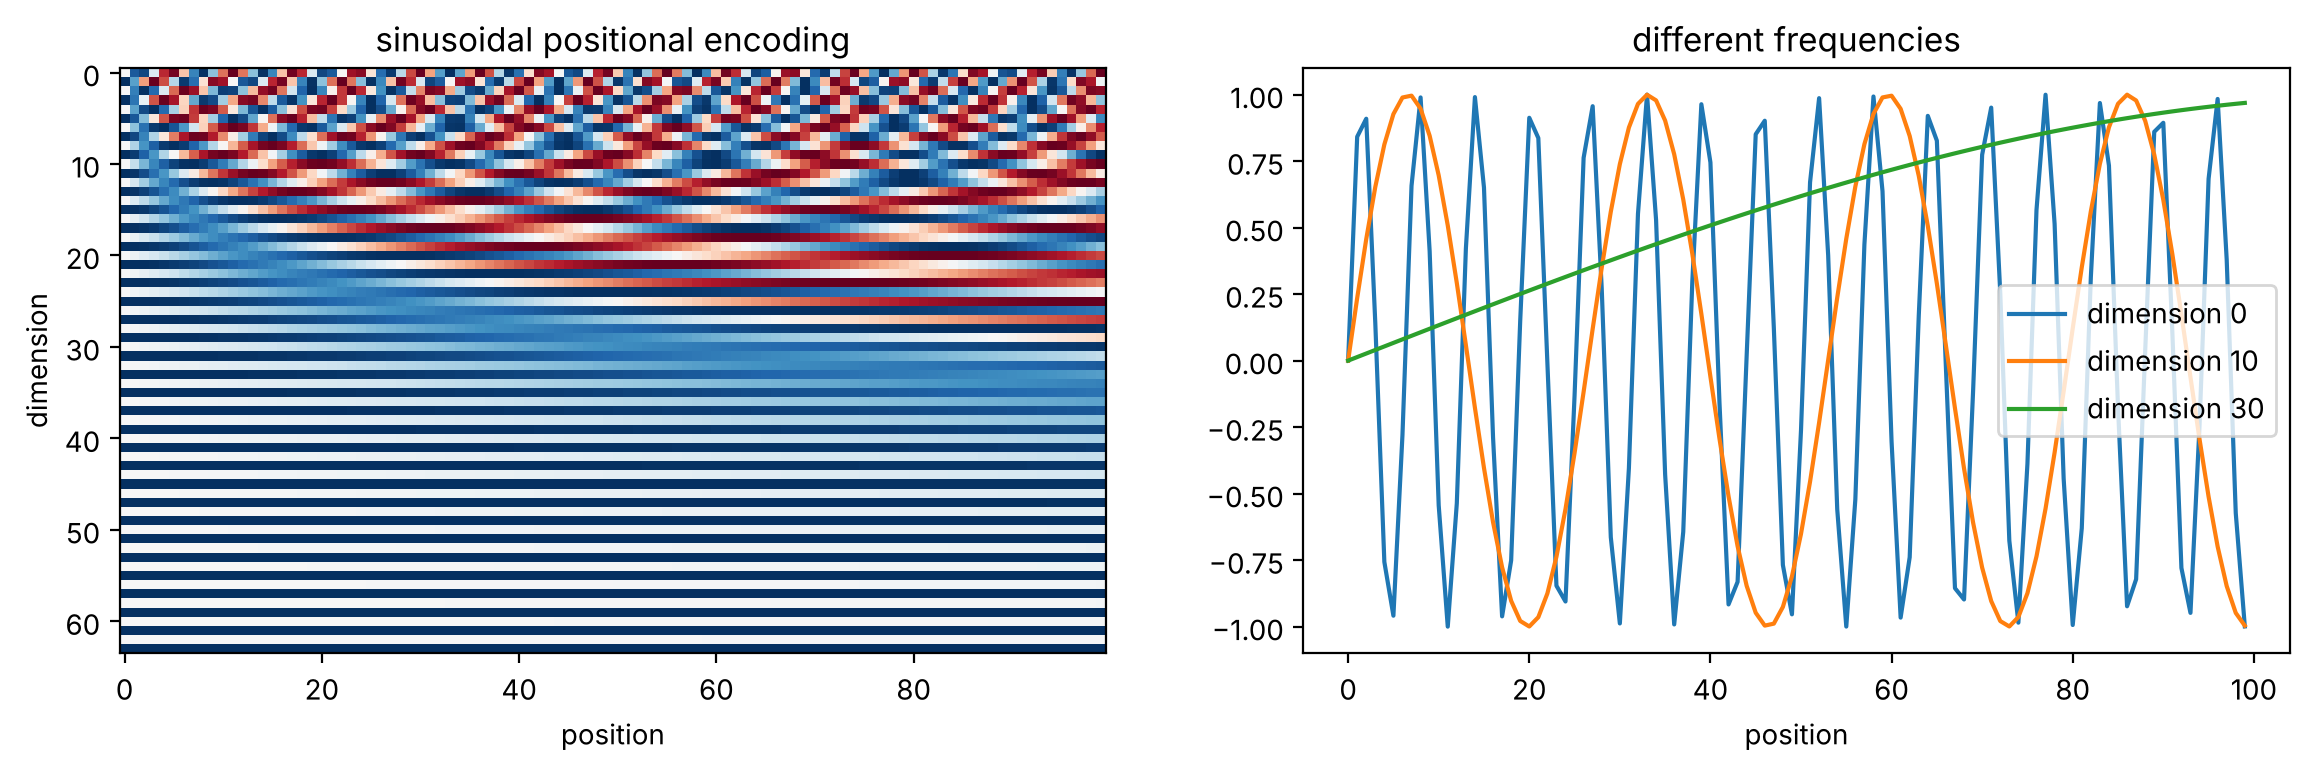

In [5]:
def sinusoidal_encoding(max_len, d):
    pos = torch.arange(max_len).unsqueeze(1)
    div = torch.exp(torch.arange(0, d, 2) * (-math.log(10000.0) / d))
    pe = torch.zeros(max_len, d)
    pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
    return pe


pe = sinusoidal_encoding(100, 64)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].imshow(pe.T, cmap='RdBu', aspect='auto'); axes[0].set_xlabel('position'); axes[0].set_ylabel('dimension')
axes[0].set_title('sinusoidal positional encoding')
for i in (0, 10, 30):
    axes[1].plot(pe[:, i], label=f'dimension {i}')
axes[1].set_xlabel('position'); axes[1].legend(); axes[1].set_title('different frequencies')
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۶. بلوک Transformer

هر بلوک دو زیرلایه دارد و دور هر کدام یک **اتصال Residual** (همان ایده ResNet) و یک **LayerNorm** (جلسه ۶) قرار می‌گیرد:

۱. **Multi-Head Self-Attention:** ارتباط بین Tokenها (ارتباط «افقی»).

۲. **شبکه Feed-Forward** موقعیتی (Position-wise FFN): یک MLP دولایه که روی هر Token **جداگانه** اعمال می‌شود؛ معمولاً با بعد میانی $4d_{\text{model}}$ و فعال‌سازی GELU. پردازش «عمودی» اطلاعات هر Token.

مقاله اصلی LayerNorm را بعد از جمع Residual قرار داد (Post-LN)؛ مدل‌های امروزی مثل GPT-2 به بعد آن را **قبل** از هر زیرلایه قرار می‌دهند (**Pre-LN**) که آموزش را پایدارتر می‌کند:

$$\mathbf{x} \leftarrow \mathbf{x} + \text{MHA}(\text{LN}(\mathbf{x})),\qquad \mathbf{x} \leftarrow \mathbf{x} + \text{FFN}(\text{LN}(\mathbf{x}))$$

</div>

In [6]:
class FeedForward(nn.Module):
    def __init__(self, d_model, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, 4 * d_model), nn.GELU(),
            nn.Linear(4 * d_model, d_model), nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.ffn = FeedForward(d_model, dropout)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))           # communication between tokens
        x = x + self.ffn(self.ln2(x))            # computation within each token
        return x


block = TransformerBlock(64, 4)
print('block output:', tuple(block(torch.randn(2, 10, 64)).shape), '| parameters:', sum(p.numel() for p in block.parameters()))

block output: (2, 10, 64) | parameters: 49984


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### سه خانواده Transformer

| خانواده | Attention | آموزش | نمونه‌ها | کاربرد |
|---|---|---|---|---|
| فقط Encoder | دوطرفه (بدون ماسک) | Masked Language Modeling | BERT، RoBERTa، ParsBERT | فهم متن: طبقه‌بندی، NER |
| فقط Decoder | علّی (با ماسک) | پیش‌بینی Token بعدی | GPT، LLaMA، Claude | تولید متن |
| Encoder–Decoder | Encoder دوطرفه + Cross-Attention | تبدیل دنباله | T5، BART، مدل اصلی ۲۰۱۷ | ترجمه، خلاصه‌سازی |

در **Cross-Attention**، Query از Decoder و Key و Value از خروجی Encoder می‌آیند؛ دقیقاً همان Attention جلسه ۱۲. در ادامه یک مدل **فقط Decoder** می‌سازیم.

## ۷. یک GPT کوچک: مدل زبانی در سطح کاراکتر

داده: **Tiny Shakespeare**، حدود یک میلیون کاراکتر از نمایشنامه‌های شکسپیر (متنی با مالکیت عمومی). مدل در هر مکان، کاراکتر بعدی را پیش‌بینی می‌کند.

</div>

In [7]:
URL = 'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt'
text = urllib.request.urlopen(URL).read().decode('utf-8')
chars = sorted(set(text))
VOCAB = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for c, i in stoi.items()}
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: ''.join(itos[i] for i in ids)

data = torch.tensor(encode(text), dtype=torch.long)
n_train = int(0.9 * len(data))
train_data, val_data = data[:n_train], data[n_train:]
print(f'{len(text):,} characters | vocabulary of {VOCAB} characters')
print(text[:300])

1,115,394 characters | vocabulary of 65 characters
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

برای آموزش، به‌طور تصادفی قطعه‌هایی به طول `BLOCK_SIZE` (طول زمینه یا Context Length) از متن برمی‌داریم. هدف همان قطعه با یک کاراکتر جابه‌جایی است؛ پس هر قطعه `BLOCK_SIZE` مسئله پیش‌بینی را همزمان در خود دارد.

</div>

In [8]:
BLOCK_SIZE = 128     # context length
BATCH_SIZE = 64


def get_batch(split):
    src = train_data if split == 'train' else val_data
    ix = torch.randint(len(src) - BLOCK_SIZE - 1, (BATCH_SIZE,))
    x = torch.stack([src[i:i + BLOCK_SIZE] for i in ix])
    y = torch.stack([src[i + 1:i + BLOCK_SIZE + 1] for i in ix])   # shifted by one character
    return x.to(device), y.to(device)


xb, yb = get_batch('train')
print('input :', repr(decode(xb[0, :40].tolist())))
print('target:', repr(decode(yb[0, :40].tolist())))

input : " dispatch; 'tis bootless to exclaim.\n\nHA"
target: "dispatch; 'tis bootless to exclaim.\n\nHAS"


In [9]:
class MiniGPT(nn.Module):
    def __init__(self, vocab, d_model=192, n_heads=6, n_layers=6, block_size=BLOCK_SIZE, dropout=0.1):
        super().__init__()
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab, d_model)
        self.pos_emb = nn.Embedding(block_size, d_model)            # learned positional embedding (as in GPT)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.Sequential(*[TransformerBlock(d_model, n_heads, dropout) for _ in range(n_layers)])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab, bias=False)
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, std=0.02)
        if isinstance(m, nn.Linear) and m.bias is not None:
            nn.init.zeros_(m.bias)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device)
        x = self.drop(self.tok_emb(idx) + self.pos_emb(pos))      # token + position information
        x = self.ln_f(self.blocks(x))
        logits = self.head(x)                                     # (B, T, vocab)
        loss = None if targets is None else F.cross_entropy(logits.view(-1, logits.shape[-1]), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]                   # never exceed the context length
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature                # only the last position predicts the next token
            if top_k is not None:
                kth = torch.topk(logits, top_k).values[:, [-1]]
                logits[logits < kth] = float('-inf')
            next_id = torch.multinomial(torch.softmax(logits, dim=-1), num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
        return idx


model = MiniGPT(VOCAB).to(device)
print(f'parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f} M')
_, loss = model(xb, yb)
print(f'initial loss {loss.item():.3f} (expected ~ ln({VOCAB}) = {math.log(VOCAB):.3f})')

parameters: 2.72 M


initial loss 4.181 (expected ~ ln(65) = 4.174)


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

آموزش با AdamW و زمان‌بند Warmup + Cosine (استاندارد Transformerها، جلسه ۵). روی GPU رایگان Colab این آموزش چند دقیقه طول می‌کشد؛ روی CPU تعداد گام‌ها را کم کنید.

</div>

In [10]:
MAX_STEPS = 3000 if device.type == 'cuda' else 300
WARMUP, LR = 100, 1e-3
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, betas=(0.9, 0.95), weight_decay=0.1)
schedule = lambda s: (s + 1) / WARMUP if s < WARMUP else 0.5 * (1 + math.cos(math.pi * (s - WARMUP) / (MAX_STEPS - WARMUP)))
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, schedule)


@torch.no_grad()
def estimate_loss(n_batches=20):
    model.eval()
    out = {split: torch.stack([model(*get_batch(split))[1] for _ in range(n_batches)]).mean().item() for split in ('train', 'val')}
    model.train()
    return out


history, start = [], time.time()
for step in range(MAX_STEPS + 1):
    if step % (MAX_STEPS // 10) == 0:
        losses = estimate_loss()
        history.append((step, losses['train'], losses['val']))
        print(f"step {step:5d} | train loss {losses['train']:.3f} | val loss {losses['val']:.3f} | {time.time() - start:.0f}s")
    xb, yb = get_batch('train')
    _, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    scheduler.step()

step     0 | train loss 4.170 | val loss 4.167 | 17s


step    30 | train loss 2.974 | val loss 3.000 | 70s


step    60 | train loss 2.572 | val loss 2.579 | 127s


step    90 | train loss 2.462 | val loss 2.465 | 182s


step   120 | train loss 2.404 | val loss 2.409 | 242s


step   150 | train loss 2.348 | val loss 2.358 | 293s


step   180 | train loss 2.291 | val loss 2.313 | 343s


step   210 | train loss 2.242 | val loss 2.259 | 391s


step   240 | train loss 2.205 | val loss 2.227 | 444s


step   270 | train loss 2.186 | val loss 2.210 | 502s


step   300 | train loss 2.183 | val loss 2.197 | 554s


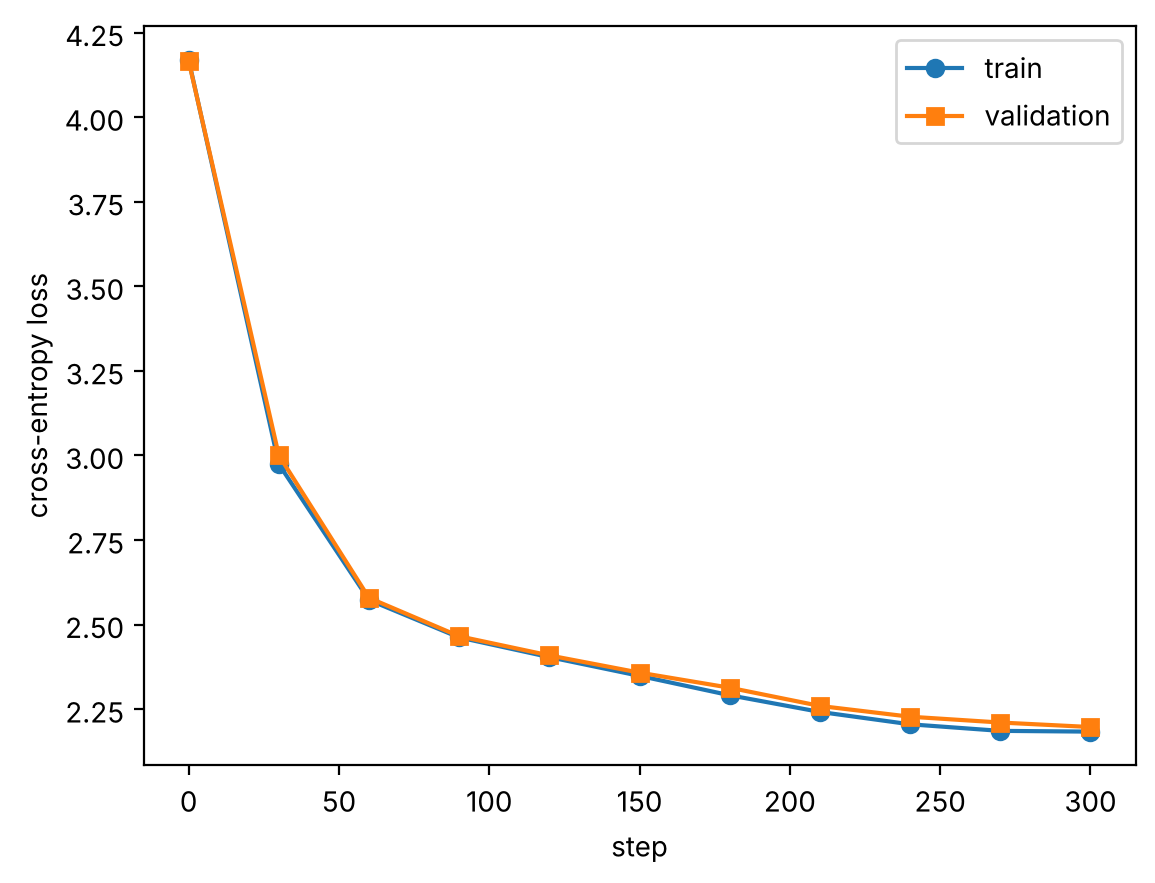

In [11]:
h = np.array(history)
plt.plot(h[:, 0], h[:, 1], 'o-', label='train'); plt.plot(h[:, 0], h[:, 2], 's-', label='validation')
plt.xlabel('step'); plt.ylabel('cross-entropy loss'); plt.legend(); plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۸. تولید متن: Temperature و Top-k

مدل در هر گام یک توزیع احتمال روی کاراکتر بعدی می‌دهد و ما از آن **نمونه‌برداری (Sampling)** می‌کنیم:

- **Temperature ($\tau$):** Logitها را بر $\tau$ تقسیم می‌کنیم. $\tau < 1$ توزیع را تیزتر و متن را محافظه‌کارتر و تکراری‌تر می‌کند؛ $\tau > 1$ توزیع را صاف‌تر و متن را خلاقانه‌تر ولی پرخطاتر.
- **Top-k:** فقط از $k$ گزینه محتمل‌تر نمونه‌برداری می‌کنیم تا گزینه‌های بسیار نامحتمل حذف شوند. (روش مشابه **Top-p** یا Nucleus Sampling کوچک‌ترین مجموعه با احتمال تجمعی $p$ را نگه می‌دارد.)

همین پارامترها را در API مدل‌های زبانی بزرگ هم می‌بینید.

</div>

In [12]:
model.eval()
prompt = torch.tensor([encode('ROMEO:\n')], device=device)
for temperature in (0.5, 1.0):
    torch.manual_seed(0)
    out = model.generate(prompt, max_new_tokens=300, temperature=temperature, top_k=20)
    print(f'===== temperature = {temperature} =====')
    print(decode(out[0].tolist()))
    print()

===== temperature = 0.5 =====
ROMEO:
Thar me thit wis lee to ca teand by thingelst,
An co at you than here he the to bear sof ande
The that o the ais pee ances is dinder non myoustsed wean stour.


SARENTEES:
The tha an she mere sthar wand to fare int ily moou norss theint o the fo o thind the me thous
As to bere the he thast sthe the 



===== temperature = 1.0 =====
ROMEO:
Thy forke thew selle louce meaman youd I tleteter
Foure you fot beere hath thio berell!
Theser most atso y weaie pee alles idart, tr non myan thed wepe ytour.


SUDENO:
Sthad thec an shup thur nere wantye thapllie-mely.
Won, hessay, int o the fleome int binkee he thim.

Kin, t yound thigst sthem mar



<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

خروجی بالا از اجرای کوتاه این نوت‌بوک روی CPU (فقط ۳۰۰ گام) است: مدل تا اینجا فقط **ساختار** نمایشنامه (نام شخصیت با حروف بزرگ و دونقطه، شکستن خطوط) و ترکیب‌های رایج حروف را یاد گرفته و کلمات هنوز بیشتر ساختگی‌اند. با ۳۰۰۰ گام روی GPU (حدود چند دقیقه در Colab)، همین مدل حدود ۲٫۷ میلیون پارامتری املای بیشتر کلمات و حتی سبک زبانی شکسپیر را یاد می‌گیرد، اما باز هم معنای منسجمی تولید نمی‌کند. GPT-3 با همین معماری (با ۱۷۵ میلیارد پارامتر، Tokenهای زیرکلمه‌ای و صدها میلیارد Token داده) آموزش دیده است؛ تفاوت اصلی در **مقیاس** است.

## ۹. نگاهی به Attention یک Head

</div>

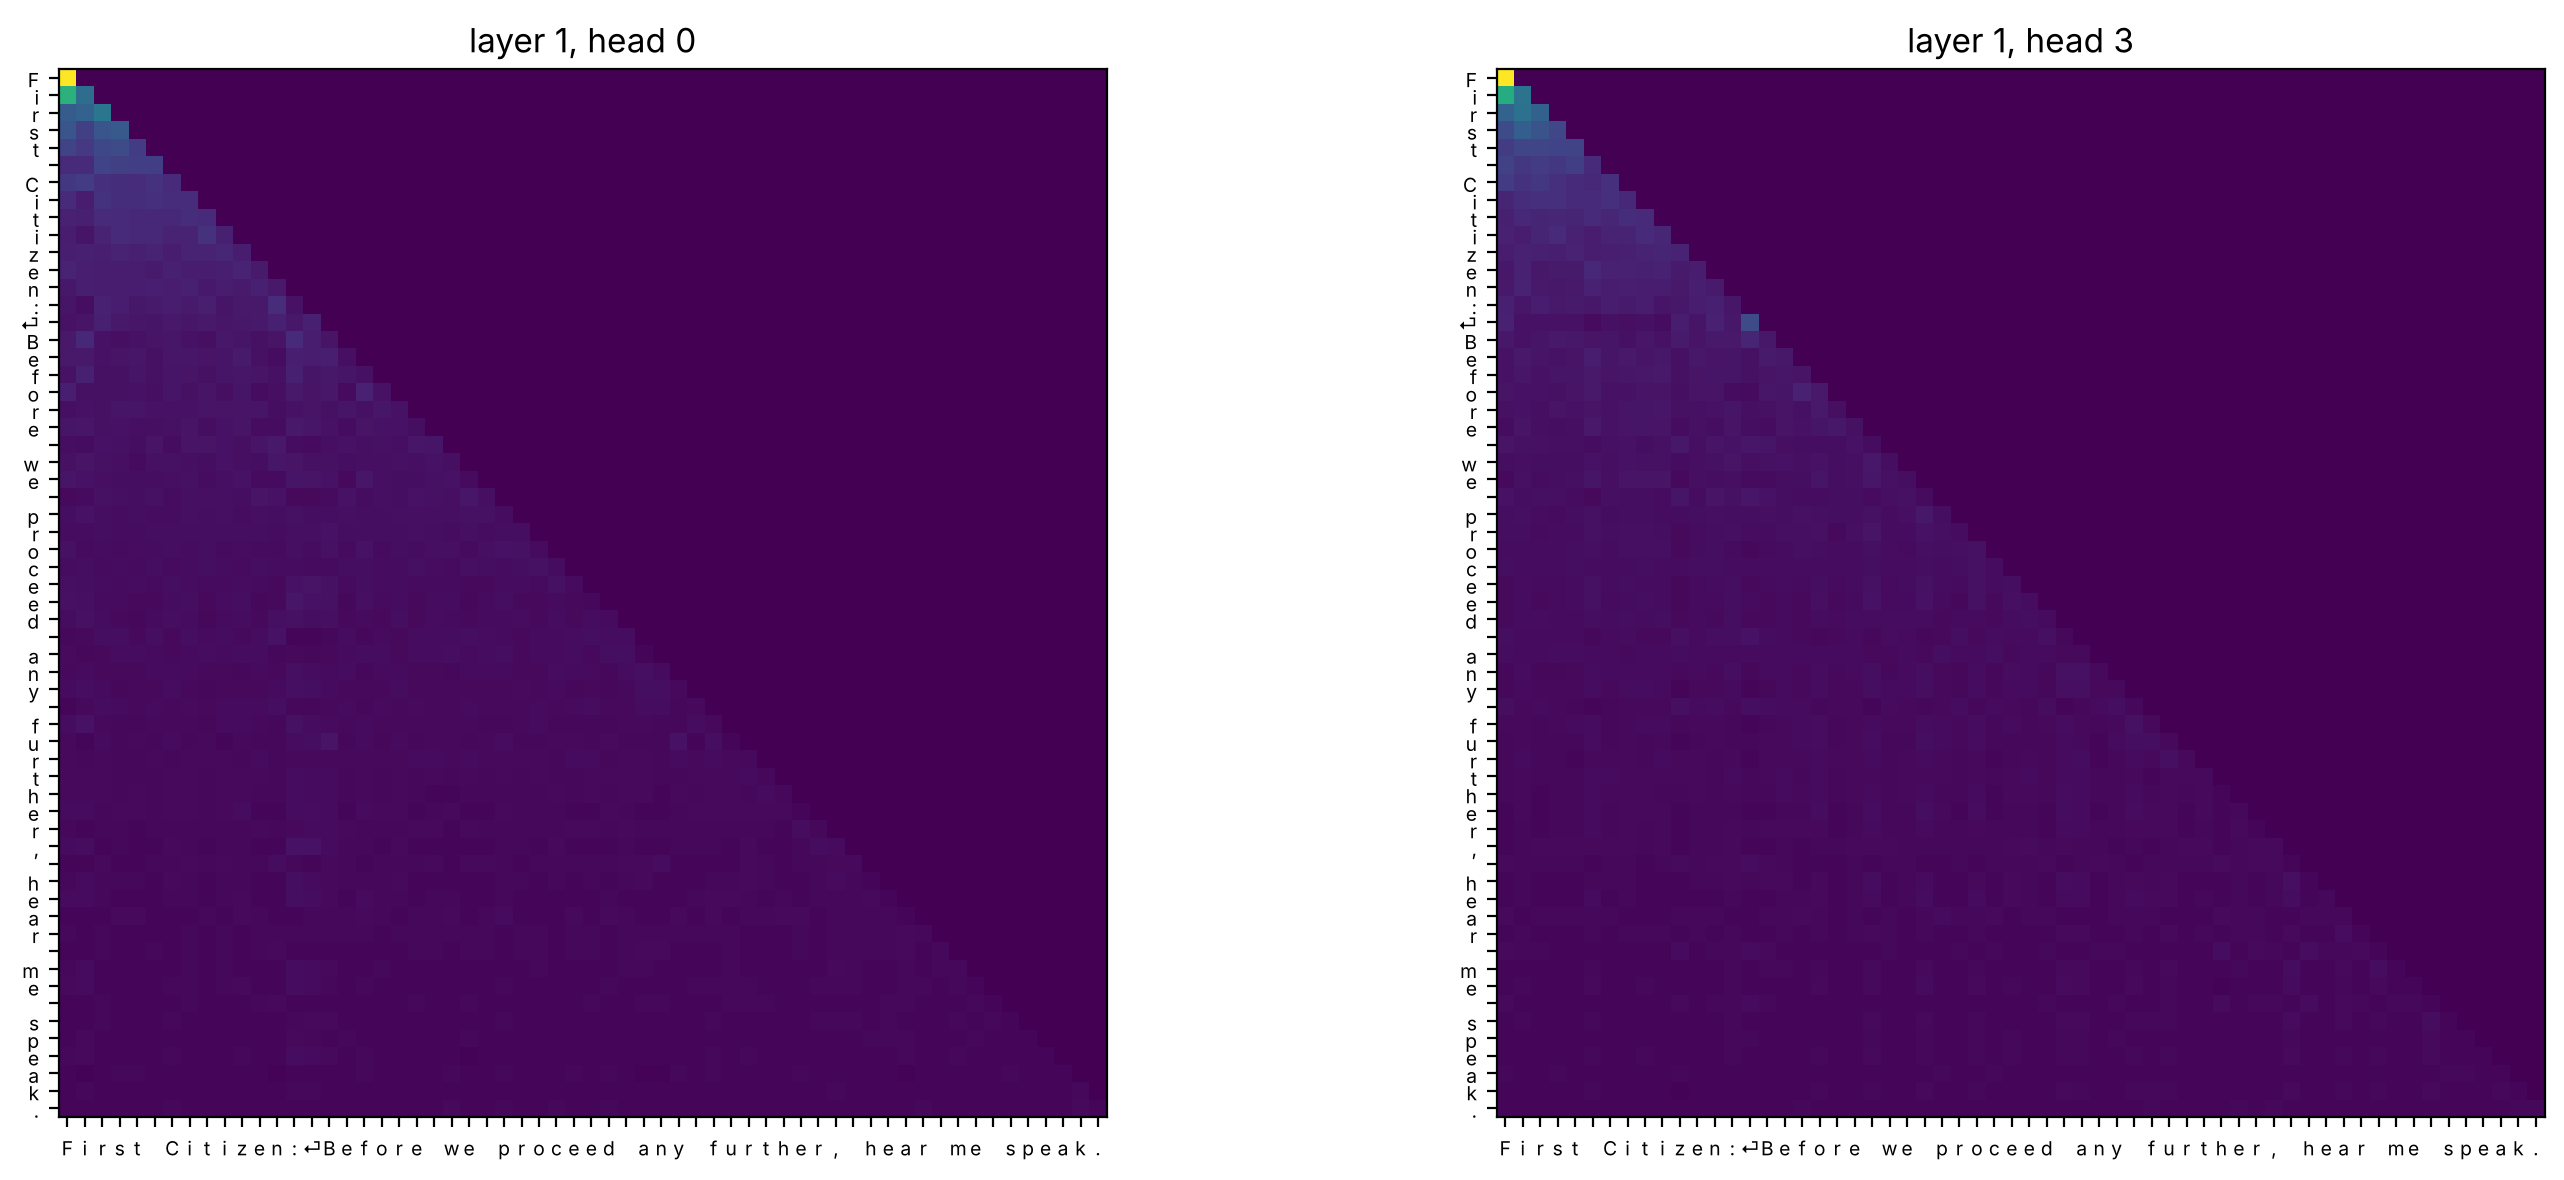

In [13]:
sample = 'First Citizen:\nBefore we proceed any further, hear me speak.'
idx = torch.tensor([encode(sample)], device=device)
with torch.no_grad():
    x = model.tok_emb(idx) + model.pos_emb(torch.arange(idx.shape[1], device=device))
    for blk in model.blocks[:1]:
        _, w = blk.attn(blk.ln1(x), return_weights=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, head in zip(axes, (0, 3)):
    ax.imshow(w[0, head].cpu(), cmap='viridis')
    ticks = list(sample.replace('\n', '⏎'))
    ax.set_xticks(range(len(ticks))); ax.set_xticklabels(ticks, fontsize=7)
    ax.set_yticks(range(len(ticks))); ax.set_yticklabels(ticks, fontsize=7)
    ax.set_title(f'layer 1, head {head}')
plt.tight_layout(); plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

به دلیل ماسک علّی، همه وزن‌ها پایین قطر اصلی‌اند. Headهای مختلف الگوهای متفاوتی یاد گرفته‌اند؛ مثلاً بعضی بیشتر به کاراکترهای بلافاصله قبلی و بعضی به ابتدای کلمه یا فاصله‌ها توجه می‌کنند.

## جمع‌بندی

- Self-Attention: هر Token با Query خود، Key همه Tokenها را می‌سنجد و میانگین وزن‌دار Valueها را می‌گیرد: $\text{softmax}(QK^\top/\sqrt{d_k})V$.
- تقسیم بر $\sqrt{d_k}$ از اشباع Softmax جلوگیری می‌کند؛ ماسک علّی نگاه به آینده را در مدل‌های زبانی ممنوع می‌کند.
- Multi-Head Attention چند رابطه را موازی و در زیرفضاهای کوچک‌تر مدل می‌کند.
- Attention به ترتیب حساس نیست؛ Positional Encoding (سینوسی یا قابل آموزش) اطلاعات موقعیت را اضافه می‌کند.
- بلوک Transformer: Pre-LN، Multi-Head Attention و FFN، هر کدام با اتصال Residual.
- سه خانواده: Encoder (BERT)، Decoder (GPT) و Encoder–Decoder (T5).
- تولید متن با نمونه‌برداری؛ Temperature و Top-k/Top-p کنترل تنوع را در دست می‌گیرند.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## تمرین‌ها

هر تمرین را در سلول کد زیر آن حل کنید. پاسخ پیشنهادی در پوشهٔ `solutions` آمده است.

۱. به‌جای `scaled_dot_product_attention` خودمان از `F.scaled_dot_product_attention(q, k, v, is_causal=True)` استفاده کنید (که روی GPU از Flash Attention بهره می‌برد) و سرعت آموزش را مقایسه کنید.

۲. Embedding موقعیت قابل آموزش را با Positional Encoding سینوسی جایگزین کنید (با `register_buffer`). آیا Loss نهایی تغییر می‌کند؟

۳. ابعاد مدل را تغییر دهید: یک بار `n_layers=2` و یک بار `d_model=96`. Loss اعتبارسنجی را بر حسب تعداد پارامتر رسم کنید.

۴. **Top-p Sampling** را به متد `generate` اضافه کنید.

۵. مدل را روی یک متن فارسی با مالکیت عمومی (مثلاً غزلیات حافظ یا شاهنامه از گنجور) آموزش دهید. به جای شکسپیر، شعر فارسی تولید کنید!

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۱.** به‌جای `scaled_dot_product_attention` خودمان از `F.scaled_dot_product_attention(q, k, v, is_causal=True)` استفاده کنید (که روی GPU از Flash Attention بهره می‌برد) و سرعت آموزش را مقایسه کنید.

</div>

In [14]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۲.** Embedding موقعیت قابل آموزش را با Positional Encoding سینوسی جایگزین کنید (با `register_buffer`). آیا Loss نهایی تغییر می‌کند؟

</div>

In [15]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۳.** ابعاد مدل را تغییر دهید: یک بار `n_layers=2` و یک بار `d_model=96`. Loss اعتبارسنجی را بر حسب تعداد پارامتر رسم کنید.

</div>

In [16]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۴.** **Top-p Sampling** را به متد `generate` اضافه کنید.

</div>

In [17]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۵.** مدل را روی یک متن فارسی با مالکیت عمومی (مثلاً غزلیات حافظ یا شاهنامه از گنجور) آموزش دهید. به جای شکسپیر، شعر فارسی تولید کنید!

</div>

In [18]:
# پاسخ خود را اینجا بنویسید
